## Olist E-Commerce: Data Exploration with DuckDB

## 1. Setup the notebook

In this notebook we load five tables of the e-commerce dataset into DuckDB and explore them with SQL before designing a data warehouse.

**What we will do**

1. Load the CSV files into DuckDB
2. Understand each table: structure, grain, keys
3. Check the relationships (foreign keys)
4. Find data quality issues
5. Build a star schema

**Tables:** `customers`, `orders`, `order_items`, `products`, `sellers`

In [1]:
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WAREHOUSE_DIR = DATA_DIR / "warehouse"
csv = RAW_DIR / "olist_orders_dataset.csv"

In [3]:
print(duckdb.sql(f"SELECT count(*) FROM '{csv}'"))

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        99441 │
└──────────────┘



### DuckDB lets query CSV data with SQL. The database file persists locally so later notebooks can reuse the loaded raw tables.

In [4]:
DB_PATH = WAREHOUSE_DIR / "ecommerce.duckdb"
con = duckdb.connect(str(DB_PATH))

In [5]:
def q(sql_str: str) -> pd.DataFrame:
    """Run a SQL query in DuckDB and return a pandas DataFrame."""
    return con.sql(sql_str).df()

## 2. Load the source tables into a **raw schema**

A Schema is a namespace that groups tables. We keep the source copies in **raw**
so that they remain distinguishable from cleaned warehouse tables we will create later.

### Define a mapping to transform column types

In [6]:
RAW_TABLES: dict[str, dict[str, str]] = {
    "customers": {"customer_zip_code_prefix": "VARCHAR"},  # keep leading zeros
    "orders": {},
    "order_items": {},
    "products": {},
    "sellers": {}
}

### Define some helper functions

In [7]:
def csv_path(table: str) -> Path:
    """"""
    return RAW_DIR / f"olist_{table}_dataset.csv"

def check_source_files(tables) -> None:
    """Fail once, list every missing file"""
    missing = [csv_path(t) for t in tables if not csv_path(t).exists()]
    if missing:
        names = "\n".join(f" - {p}" for p in missing)
        raise FileNotFoundError(f"Missing CSV files: {names}")

#### Define schema name for source data

In [8]:
RAW_SCHEMA = "raw"

### Load data into source tables

In [9]:
def load_raw_table(con: duckdb.DuckDBPyConnection, table: str, column_types: dict[str, str]) -> int:
    target = f'{RAW_SCHEMA}."{table}"'
    source = con.read_csv(str(csv_path(table)), header=True, dtype=column_types or None)
    con.execute(f"DROP TABLE IF EXISTS {target}")
    source.to_table(target)
    return con.execute(f"SELECT count(*) FROM {target}").fetchone()[0]

### Sanity check if we have all required source files

In [10]:
check_source_files(RAW_TABLES)

### Create **RAW_SCHEMA** if it does not exist

In [11]:
con.execute(f"CREATE SCHEMA IF NOT EXISTS {RAW_SCHEMA}")

### Execute **load_raw_table** to load all source data

In [12]:
row_counts = {t: load_raw_table(con, t, types) for t, types in RAW_TABLES.items()}

### Check count of rows inserted into each `raw`.`<table>`

In [13]:
pd.DataFrame(row_counts.items(), columns=["table_name", "row_count"])

,table_name,row_count
0,customers,99441
1,orders,99441
2,order_items,112650
3,products,32951
4,sellers,3095


## 3. Look at each table

For every table we ask: **what does one row represent?** This is the *grain*. Getting the grain right is the most important step in dimensional modeling.

In [14]:
for t in RAW_TABLES:
    print(f"----- {t} -----")
    display(q(f"DESCRIBE raw.{t}")[["column_name", "column_type", "null"]])
    display(q(f"SELECT * FROM raw.{t} LIMIT 5"))

----- customers -----


,column_name,column_type,null
0,customer_id,VARCHAR,YES
1,customer_unique_id,VARCHAR,YES
2,customer_zip_code_prefix,VARCHAR,YES
3,customer_city,VARCHAR,YES
4,customer_state,VARCHAR,YES


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


----- orders -----


,column_name,column_type,null
0,order_id,VARCHAR,YES
1,customer_id,VARCHAR,YES
2,order_status,VARCHAR,YES
3,order_purchase_timestamp,TIMESTAMP,YES
4,order_approved_at,TIMESTAMP,YES
5,order_delivered_carrier_date,TIMESTAMP,YES
6,order_delivered_customer_date,TIMESTAMP,YES
7,order_estimated_delivery_date,TIMESTAMP,YES


...

,column_name,column_type,null
0,product_id,VARCHAR,YES
1,product_category_name,VARCHAR,YES
2,product_name_lenght,BIGINT,YES
3,product_description_lenght,BIGINT,YES
4,product_photos_qty,BIGINT,YES
5,product_weight_g,BIGINT,YES
6,product_length_cm,BIGINT,YES
7,product_height_cm,BIGINT,YES
8,product_width_cm,BIGINT,YES


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15
3,cef67bcfe19066a932b7673e239eb23d,bebes,27,261,1,371,26,4,26
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37,402,4,625,20,17,13


----- sellers -----


,column_name,column_type,null
0,seller_id,VARCHAR,YES
1,seller_zip_code_prefix,VARCHAR,YES
2,seller_city,VARCHAR,YES
3,seller_state,VARCHAR,YES


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


**Grain (what one row is)**

- `customers`: one customer_id. Olist makes a new customer_id for every order, so it is one customer per order and not one person.
- `orders`: one order.
- `order_items`: one item inside an order. `order_item_id` is the item number (1, 2, 3, ...) within that order.
- `products`: one product.
- `sellers`: one seller.

`SUMMARIZE`profiles every column is one command: min, max, average, null percentage,
approximate distinct count.

In [15]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244663,21.16306476327699,112650,0.0


In [16]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244663,21.16306476327699,112650,0.0


In [17]:
q("SUMMARIZE raw.products")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,32951,0.00
1,product_category_name,VARCHAR,agro_industria_e_comercio,utilidades_domesticas,66,NaN,NaN,NaN,NaN,NaN,32951,1.85
2,product_name_lenght,BIGINT,5,76,64,48.47694876472589,10.245740725237287,42,51,57,32951,1.85
3,product_description_lenght,BIGINT,4,3992,2781,771.4952846232337,635.1152246349538,339,594,973,32951,1.85
4,product_photos_qty,BIGINT,1,20,20,2.1889861166939797,1.7367656379315435,1,1,3,32951,1.85
5,product_weight_g,BIGINT,0,40425,2155,2276.4724877841513,4282.038730977024,300,701,1883,32951,0.01
6,product_length_cm,BIGINT,7,105,97,30.81507784758263,16.914458054065953,18,25,39,32951,0.01
7,product_height_cm,BIGINT,2,105,99,16.937661234028347,13.637554061749569,8,13,21,32951,0.01
8,product_width_cm,BIGINT,6,118,92,23.196728277034204,12.079047453227794,15,20,30,32951,0.01


## 4. Primary Keys

A **primary key** uniquely identifies a row. A column is a valid candidate only if `count(*) = count(distinct ...)` and it has no nulls.

- A **composite key** uses several columns together (`order_items`)
- A **natural key** comes from the business (`customer_unique_id`).
- A **surrogate key** is generated by the warehouse (`customer_key = 1, 2, 3...`)

In [18]:
q("""
SELECT 'customers.customer_id'         AS candidate, count(*) AS n, count(DISTINCT customer_id) AS n_distinct, count(*) FILTER (customer_id IS NULL) AS n_null FROM raw.customers
UNION ALL SELECT 'customers.customer_unique_id',         count(*), count(DISTINCT customer_unique_id), count(*) FILTER (customer_unique_id IS NULL) FROM raw.customers
UNION ALL SELECT 'orders.order_id',                      count(*), count(DISTINCT order_id), count(*) FILTER (order_id IS NULL) FROM raw.orders
UNION ALL SELECT 'order_items.order_id (alone)',         count(*), count(DISTINCT order_id), count(*) FILTER (order_id IS NULL) FROM raw.order_items
UNION ALL SELECT 'order_items(order_id, order_item_id)', count(*), count(DISTINCT (order_id, order_item_id)), count(*) FILTER (order_id IS NULL OR order_item_id IS NULL) FROM raw.order_items
UNION ALL SELECT 'products.product_id',                  count(*), count(DISTINCT product_id), count(*) FILTER (product_id IS NULL) FROM raw.products
UNION ALL SELECT 'sellers.seller_id',                    count(*), count(DISTINCT seller_id), count(*) FILTER (seller_id IS NULL) FROM raw.sellers
""")

,candidate,n,n_distinct,n_null
0,customers.customer_id,99441,99441,0
1,customers.customer_unique_id,99441,96096,0
2,orders.order_id,99441,99441,0
3,order_items.order_id (alone),112650,98666,0
4,"order_items(order_id, order_item_id)",112650,112650,0
5,products.product_id,32951,32951,0
6,sellers.seller_id,3095,3095,0


Primary keys (n = n_distinct and n_null = 0):

| table | primary key |
|---|---|
| customers | customer_id |
| orders | order_id |
| order_items | (order_id, order_item_id) |
| products | product_id |
| sellers | seller_id |

`order_id` alone is not unique in order_items because one order can have many items, so the key needs both columns. `customer_unique_id` is not unique either.

In [19]:
q("""
SELECT count(DISTINCT customer_id) AS customer_ids,
       count(DISTINCT customer_unique_id) AS unique_customers,
       max(n) AS max_ids_per_person
FROM (SELECT customer_id, customer_unique_id,
             count(*) OVER (PARTITION BY customer_unique_id) AS n
      FROM raw.customers)
""")

,customer_ids,unique_customers,max_ids_per_person
0,99441,96096,17


`customer_unique_id` is the actual person. One person can have up to 17 customer_ids (one for each order), so counting customers should use `count(DISTINCT customer_unique_id)`.

## 4. Foreign key relationships

```
customers 1 ---- N orders 1 ---- N order_items N ---- 1 products
```

A foreign key is healthy when every value exists in the parent table. An **orphan** is
a child row with no parent.

In [20]:
q("""
SELECT 'orders without customer' AS check_name, count(*) AS n
  FROM raw.orders o ANTI JOIN raw.customers c USING (customer_id)
UNION ALL SELECT 'items without order', count(*)
  FROM raw.order_items i ANTI JOIN raw.orders o USING (order_id)
UNION ALL SELECT 'items without product', count(*)
  FROM raw.order_items i ANTI JOIN raw.products p USING (product_id)
UNION ALL SELECT 'items without seller', count(*)
    FROM raw.order_items i ANTI JOIN raw.sellers s USING (seller_id)
UNION ALL SELECT 'orders without items', count(*)
  FROM raw.orders o ANTI JOIN raw.order_items i USING (order_id)
""")

,check_name,n
0,orders without customer,0
1,items without order,0
2,items without product,0
3,items without seller,0
4,orders without items,775


No orphans in the child-to-parent direction. But 775 orders have no items. An **INNER JOIN** from orders
to items would silently remove them.

## Cardinality

Relationships from the orphan check above (the child is the table holding the FK):

| parent | child | column |
|---|---|---|
| customers | orders | customer_id |
| orders | order_items | order_id |
| products | order_items | product_id |
| sellers | order_items | seller_id |

Count the children of every parent. LEFT JOIN so that parents with no children show up as 0.

In [21]:
q("""
SELECT 'customers -> orders' AS relationship, min(n) AS min_children, max(n) AS max_children
FROM (SELECT c.customer_id, count(o.order_id) AS n
      FROM raw.customers c LEFT JOIN raw.orders o USING (customer_id)
      GROUP BY c.customer_id)
UNION ALL
SELECT 'orders -> order_items', min(n), max(n)
FROM (SELECT o.order_id, count(i.order_id) AS n
      FROM raw.orders o LEFT JOIN raw.order_items i USING (order_id)
      GROUP BY o.order_id)
UNION ALL
SELECT 'products -> order_items', min(n), max(n)
FROM (SELECT p.product_id, count(i.product_id) AS n
      FROM raw.products p LEFT JOIN raw.order_items i USING (product_id)
      GROUP BY p.product_id)
UNION ALL
SELECT 'sellers -> order_items', min(n), max(n)
FROM (SELECT s.seller_id, count(i.seller_id) AS n
      FROM raw.sellers s LEFT JOIN raw.order_items i USING (seller_id)
      GROUP BY s.seller_id)
""")

,relationship,min_children,max_children
0,customers -> orders,1,1
1,orders -> order_items,0,21
2,products -> order_items,1,527
3,sellers -> order_items,1,2033


| relationship | min | max | each parent has | each child has |
|---|---|---|---|---|
| customers places orders | 1 | 1 | one or many orders | exactly one customer |
| orders contains order_items | 0 | 21 | zero or many items | exactly one order |
| products appears in order_items | 1 | 527 | one or many items | exactly one product |
| sellers sells order_items | 1 | 2033 | one or many items | exactly one seller |

Every child has exactly one parent since there are no orphans and the FK columns have no nulls (a null FK would also show up in the ANTI JOIN).

For customers -> orders the data is actually exactly one (max = 1) because customer_id is created per order. I still drew one or many on the ERD because a customer can order again.

Only orders -> order_items has parents with zero children (the 775 orders), so that is the only line that gets a circle.

order_items is linked to three tables. Check if it hides a many-to-many:

In [22]:
q("""
SELECT
  (SELECT count(*) FROM (SELECT order_id FROM raw.order_items
                         GROUP BY order_id HAVING count(DISTINCT product_id) > 1)) AS orders_with_several_products,
  (SELECT count(*) FROM (SELECT product_id FROM raw.order_items
                         GROUP BY product_id HAVING count(DISTINCT order_id) > 1)) AS products_in_several_orders,
  (SELECT count(*) FROM (SELECT order_id FROM raw.order_items
                         GROUP BY order_id HAVING count(DISTINCT seller_id) > 1)) AS orders_with_several_sellers
""")

,orders_with_several_products,products_in_several_orders,orders_with_several_sellers
0,3236,13387,1278


An order can have several products and a product can be in several orders, so orders and products are many-to-many. order_items is the junction table that resolves it (and the same for orders and sellers).

## 5. Data Quality

we check five dimensions: completeness(nulls), uniqueness, validity (values in a sensible range),
consistency (fields agree), timeliness (coverage)

### 5.1 Orders with no items

#### Exercise 1

In [23]:
q("""
SELECT o.order_status, count(*) AS orders_without_items
FROM raw.orders o
ANTI JOIN raw.order_items i USING (order_id)
GROUP BY o.order_status
ORDER BY orders_without_items DESC
""")

,order_status,orders_without_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


775 orders have no items. Almost all are `unavailable` or `canceled`, but 8 of them are created/invoiced/shipped, which is strange for an order with nothing in it.

### 5.2 Check order status and class imbalance

#### Exercise 2

In [24]:
q("""
SELECT order_status,
       count(*) AS n,
       round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
FROM raw.orders
GROUP BY order_status
ORDER BY n DESC
""")

,order_status,n,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


97% of orders are delivered and every other status is around 1% or less, so the classes are very imbalanced. For example canceled is only 0.63%.

### 5.3 Missing and inconsistent timestamps

#### Exercise 3

In [25]:
q("""
SELECT
    count(*) FILTER (WHERE order_approved_at IS NULL)             AS approved_null,
    count(*) FILTER (WHERE order_delivered_carrier_date IS NULL)  AS carrier_null,
    count(*) FILTER (WHERE order_delivered_customer_date IS NULL) AS delivered_null,
    count(*) FILTER (WHERE order_status = 'delivered'
                       AND order_delivered_customer_date IS NULL) AS delivered_but_no_date,
    count(*) FILTER (WHERE order_delivered_carrier_date > order_delivered_customer_date) AS carrier_after_customer
FROM raw.orders
""")

,approved_null,carrier_null,delivered_null,delivered_but_no_date,carrier_after_customer
0,160,1783,2965,8,23


Most of the nulls are expected because the order never reached that step (canceled, still shipping, ...). The real problems are 8 delivered orders without a delivery date and 23 orders that reached the customer before the carrier picked them up.

### 5.4 Time coverage

#### Exercise 4

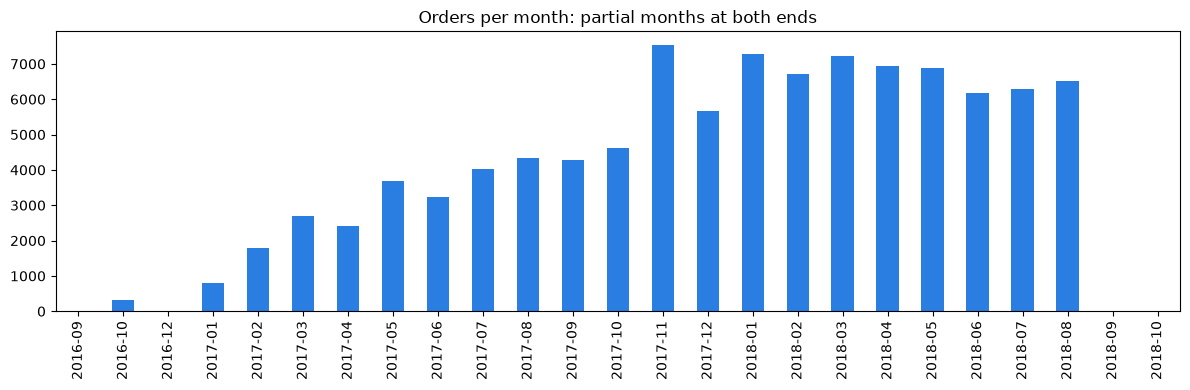

In [26]:
monthly = q("""
SELECT strftime(order_purchase_timestamp, '%Y-%m') AS month,
       count(*) AS orders
FROM raw.orders
GROUP BY month
ORDER BY month
""")
ax = monthly.plot.bar(x="month", y="orders", figsize=(12, 4), legend=False, color="#2a7de1")
ax.set_title("Orders per month: partial months at both ends")
ax.set_xlabel("")
plt.tight_layout(); plt.show()

The data goes from 2016-09 to 2018-10. 2016-09, 2016-12, 2018-09 and 2018-10 only have a handful of orders and 2016-11 is missing completely, so for trends it is better to use 2017-01 to 2018-08 only.

### 5.5 Product completeness check

#### Exercise 5

In [27]:
q("""
SELECT count(*) AS products,
       count(*) FILTER (WHERE product_category_name IS NULL) AS category_null,
       count(*) FILTER (WHERE product_weight_g IS NULL) AS weight_null,
       count(*) FILTER (WHERE product_weight_g = 0) AS weight_zero,
       count(DISTINCT product_category_name) AS n_categories
FROM raw.products
""")

,products,category_null,weight_null,weight_zero,n_categories
0,32951,610,2,4,73


610 products have no category, 2 have no weight and 4 have a weight of 0 g, which is not realistic. There are 73 categories.